In [1]:
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

load_dotenv(PROJECT_ROOT / ".env")
openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")

# 키의 일부도 출력하지 않습니다 (노트북 출력이 저장소에 남기 때문)
print("API 키 로드 완료 (값은 출력하지 않음)")

API 키 로드 완료 (값은 출력하지 않음)


In [2]:
# 키가 실제로 유효한지 확인합니다.
from openai import OpenAI, AuthenticationError

try:
    OpenAI(api_key=openai_api_key).models.list()
    print("OPENAI_API_KEY 가 유효합니다.")
except AuthenticationError:
    raise ValueError("OPENAI_API_KEY 가 유효하지 않습니다. .env 파일을 확인하세요.")

OPENAI_API_KEY 가 유효합니다.


In [3]:
pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"

with open(pkl_path, "rb") as f:
    data = pickle.load(f)

texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

print(f"texts 개수: {len(texts)}")
print(f"tables 개수: {len(tables)}")
print(f"texts_2k_token 개수: {len(texts_2k_token)}")

figures_dir = PROJECT_ROOT / "data" / "figures"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")

texts 개수: 9
tables 개수: 4
texts_2k_token 개수: 6
figures_dir 존재 여부: True


In [4]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI


def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 요약본을 생성합니다.

    texts          : 텍스트 리스트
    tables         : 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부
    """

    # Prompt 한국어 버전 (표는 수치가 중요하므로 '수치·항목명 유지' 한 줄을 추가)
    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
표라면 표 제목, 종속변수, 비교 항목과 핵심 수치를 요약에 포함해주세요.
요약할 표 또는 텍스트: {element}"""

    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    # 요약 체인 = 입력 포장 + 프롬프트 + LLM + 출력 파서
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []

    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 2})

    return text_summaries, table_summaries


print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


In [5]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수    :", len(table_summaries))

요약 완료 — 12.7초 소요
텍스트 요약 수: 6
표 요약 수    : 4


In [6]:
print("_" * 60)
print("[원본] texts_2k_token[0] - 앞 300자")
print("_" * 60)
print(texts_2k_token[0][:300])
print()

print("_" * 60)
print("[요약] text_summaries[0]")
print("_" * 60)
print(text_summaries[0])
print()

origin = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률 : {origin}자 -> {summ}자 ({(1 - summ / origin) * 100:.1f}%)")

____________________________________________________________
[원본] texts_2k_token[0] - 앞 300자
____________________________________________________________
KDI

2026 Vol. 154154

FOCUS

KDI FOCUS 2026년 6월 30일(통권 제154호) 자료문의 KDI 홍보팀(044-550-4030) 집필자 이공 연구위원(044-550-4018) KDI FOCUS는 시의성 있는 경제 ‧ 사회적 이슈를 간략하게 정리한 시론 성격의 자료임. 본 포커스의 내용은 집필자 개인의 의견이며 본원의 공식 견해가 아님.

온라인 유통시장이 급속도로 성장하고 있는 상황에서, 대형마트는 온라인과의 경쟁으로 매출 감소가 확인된 반면, SSM, 편의점 등 일 부 오프라인 유통업은 근거리 기반

____________________________________________________________
[요약] text_summaries[0]
____________________________________________________________
**KDI FOCUS 2026년 6월 30일 (통권 제154호) 요약**

- **주제**: 온라인 유통의 성장과 유통시장 정책 개선 방향
- **핵심 내용**: 
  - 온라인 유통시장이 급속히 성장하며, 대형마트는 매출 감소를 겪고 있음.
  - SSM 및 편의점 등 일부 오프라인 유통업체는 근거리 기반의 차별화된 수요로 시장이 확장됨.
  - 현행 유통산업발전법은 오프라인 중심으로 설계되어 온라인 유통의 급성장에 대응하지 못하고 있음.
  - 2024년 온라인 유통시장 규모는 약 97.74조원으로, 2018년의 48.05조원의 두 배 이상 증가.
  - 전체 유통시장 매출은 2024년 8.2% 증가, 온라인 유통은 15.0% 증가.
  - 2023년 온라인 유통시장 매출 비중이 전체 유통시장의 50%

In [7]:
if table_summaries:
    print(f"표 요약 {len(table_summaries)}건 생성됨\n")
    for i, (table, summary) in enumerate(zip(tables, table_summaries)):
        print("=" * 60)
        print(f"[표 {i + 1}] 원본(앞 300자)")
        print("=" * 60)
        print(table[:300])
        print()
        print("=" * 60)
        print(f"[표 {i + 1}] 요약")
        print("=" * 60)
        print(summary)
        print()
else:
    print("표 요약이 비어 있습니다. (1) hi_res 사용 여부 (2) 표가 그림으로 그려졌는지 확인")

표 요약 4건 생성됨

[표 1] 원본(앞 300자)
종속변수: 오프라인 매출 합계 (로그화) (1) 매출 (2) 결제 1건당 매출 (3) 소비자 1인당 결제 건수 (4) 업체 1개당 소비자 수 (5) 업체 수 1인당 온라인 지출 0.186*** -0.020 0.009 0.045** 0.152*** (로그화) (0.032) (0.020) (0.007) (0.019) (0.018) 지역/월 고정효과, 통제변수, 도구변수 포함 포함 포함 포함 포함 관측치 수 197,089 197,089 197,089 197,089 197,089 읍면동 수 3,518 3,518 3,518 3,518 3,5

[표 1] 요약
**표 제목:** 오프라인 매출 합계 (로그화) 분석

**종속변수:** 오프라인 매출 합계 (로그화)

**비교 항목 및 핵심 수치:**
1. 매출: 0.186*** (표준오차: 0.032)
2. 결제 1건당 매출: -0.020 (표준오차: 0.020)
3. 소비자 1인당 결제 건수: 0.009 (표준오차: 0.007)
4. 업체 1개당 소비자 수: 0.045** (표준오차: 0.019)
5. 업체 수 1인당 온라인 지출: 0.152*** (표준오차: 0.018)

**추가 정보:** 지역/월 고정효과, 통제변수, 도구변수 포함. 관측치 수: 197,089, 읍면동 수: 3,518.

[표 2] 원본(앞 300자)
우선 오프라인 유통업체들의 매출을 요인별로 구분하여 그 기여도를 분석했다. <표 1> 결제 1건당 매출(2)이나 소비자 1인당 결제 건수(3)와 같은 질적인 측면에서는 소비자 들의 온라인 지출이 증가함에도 불구하고 유의미한 변화가 관찰되지 않았다. 그러나 업

[표 2] 요약
**표 1 요약: 오프라인 유통업체 매출 기여도 분석**

- **종속변수**: 매출
- **비교 항목**: 결제 1건당 매출, 소비자 1인당 결제 건수
- **핵심 수치**: 소비자들의 온라인 지출 증가에도 불구하고 질적인 측면에서 유의미한 변화 없음.

[표 3] 원본(앞 

In [8]:
import base64
from langchain_core.messages import HumanMessage


def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        encoded_string = base64.b64encode(image_file.read()).decode("utf-8")
    return encoded_string


image_files = sorted(
    f for f in figures_dir.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print("=" * 50)
if image_files:
    sample_b64 = encode_image(image_files[0])
    print(f"첫 번째 이미지 파일: {image_files[0].name}")
    print(f"인코딩 문자열 길이: {len(sample_b64):,}")
    print(f"인코딩 문자열 앞 100자: {sample_b64[:100]}")

첫 번째 이미지 파일: figure-1-1.jpg
인코딩 문자열 길이: 16,040
인코딩 문자열 앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


In [9]:
IMG_PROMPT = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
If the image is a chart, include the title, axis names, value ranges and the overall trend.
If the image is a table, include the table title, column headers and the key numbers.
The summary should be written in Korean (Hangul)."""


def image_summarize(img_base64, prompt):
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)

    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {
                "type": "image_url",
                "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
            },
        ])
    ])
    return msg.content


# 테스트: 첫 번째 이미지
print(image_summarize(sample_b64, IMG_PROMPT))

이미지 요약: KDI 로고. "KDI"라는 단어가 굵은 글씨로 표기된 단순한 디자인.


In [10]:
def generate_img_summaries(path):
    """
    이미지의 요약과 Base64 인코딩 문자열을 생성

    path: Unstructured에 의해 추출된 이미지 파일들의 경로
    """
    img_base64_list = []   # Base64로 인코딩된 이미지
    image_summaries = []   # 이미지 요약문

    for img_file in sorted(os.listdir(path)):
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, IMG_PROMPT))

    return img_base64_list, image_summaries


start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))

이미지 요약 완료 — 8.9초 소요
요약된 이미지 수: 6


[0] figure-1-1.jpg


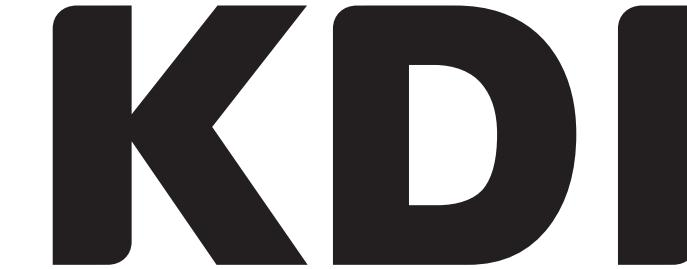

요약: 이미지에는 "KDI"라는 텍스트가 포함되어 있습니다. 이는 한국개발연구원(Korea Development Institute)을 의미하는 로고 또는 브랜딩 요소입니다.

[1] figure-1-2.jpg


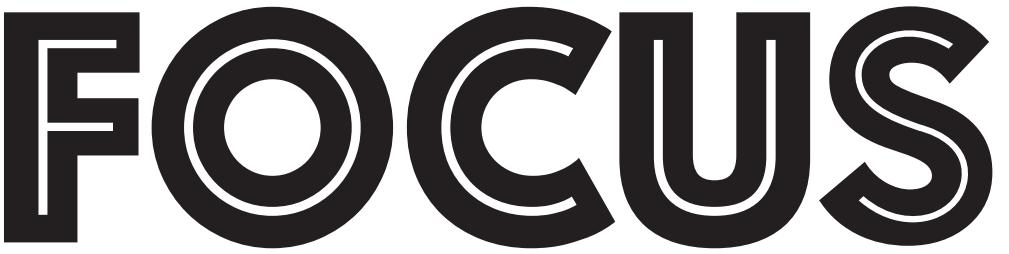

요약: 이미지는 "FOCUS"라는 단어로 구성된 텍스트를 포함하고 있습니다. 글자는 두꺼운 세리프체로, 고유한 디자인이 특징입니다.

[2] figure-1-3.jpg


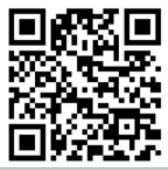

요약: 이 이미지는 QR 코드입니다. QR 코드는 정보를 저장하고 빠르게 스캔할 수 있는 패턴으로 구성되어 있습니다.

[3] figure-1-4.jpg


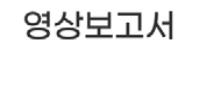

요약: 영상보고서라는 제목의 이미지가 포함되어 있습니다.

[4] figure-1-5.jpg


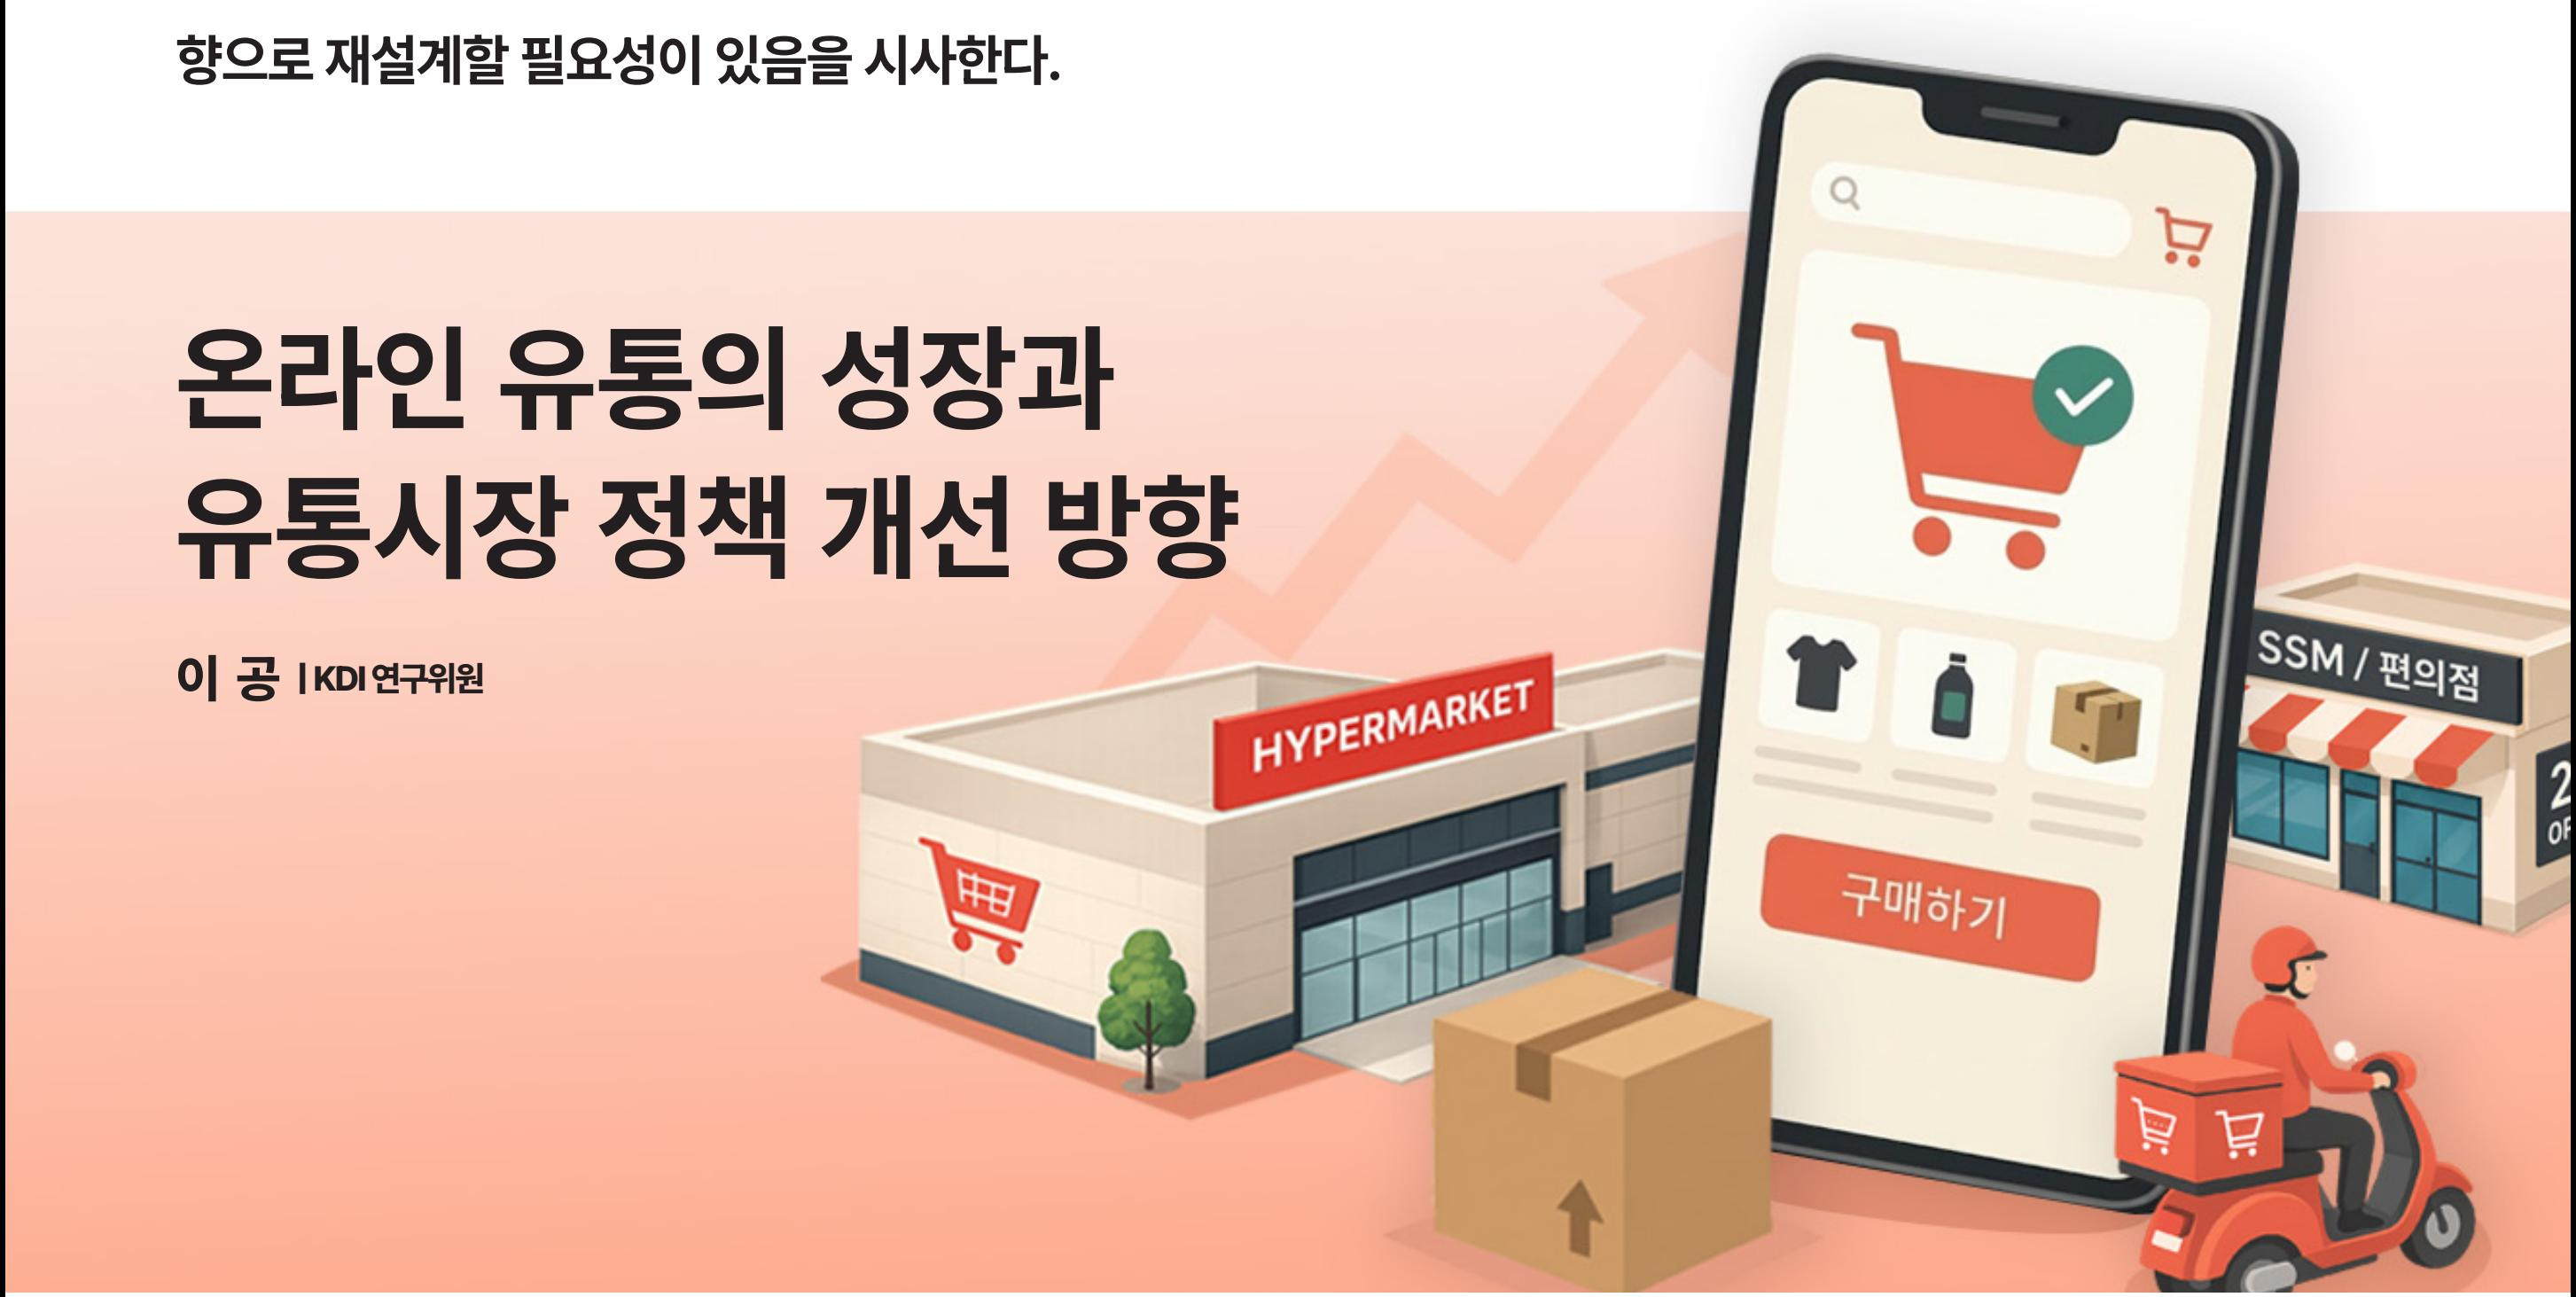

요약: 이미지 요약: "온라인 유통의 성장과 유통시장 정책 개선 방향"이라는 제목의 슬라이드. 스마트폰 화면에는 장바구니 아이콘과 상품 목록이 표시되고 있으며, 하이퍼마켓과 배달 서비스를 나타내는 일러스트가 포함됨. KDI 연구원 이공 저자.

[5] figure-3-6.jpg


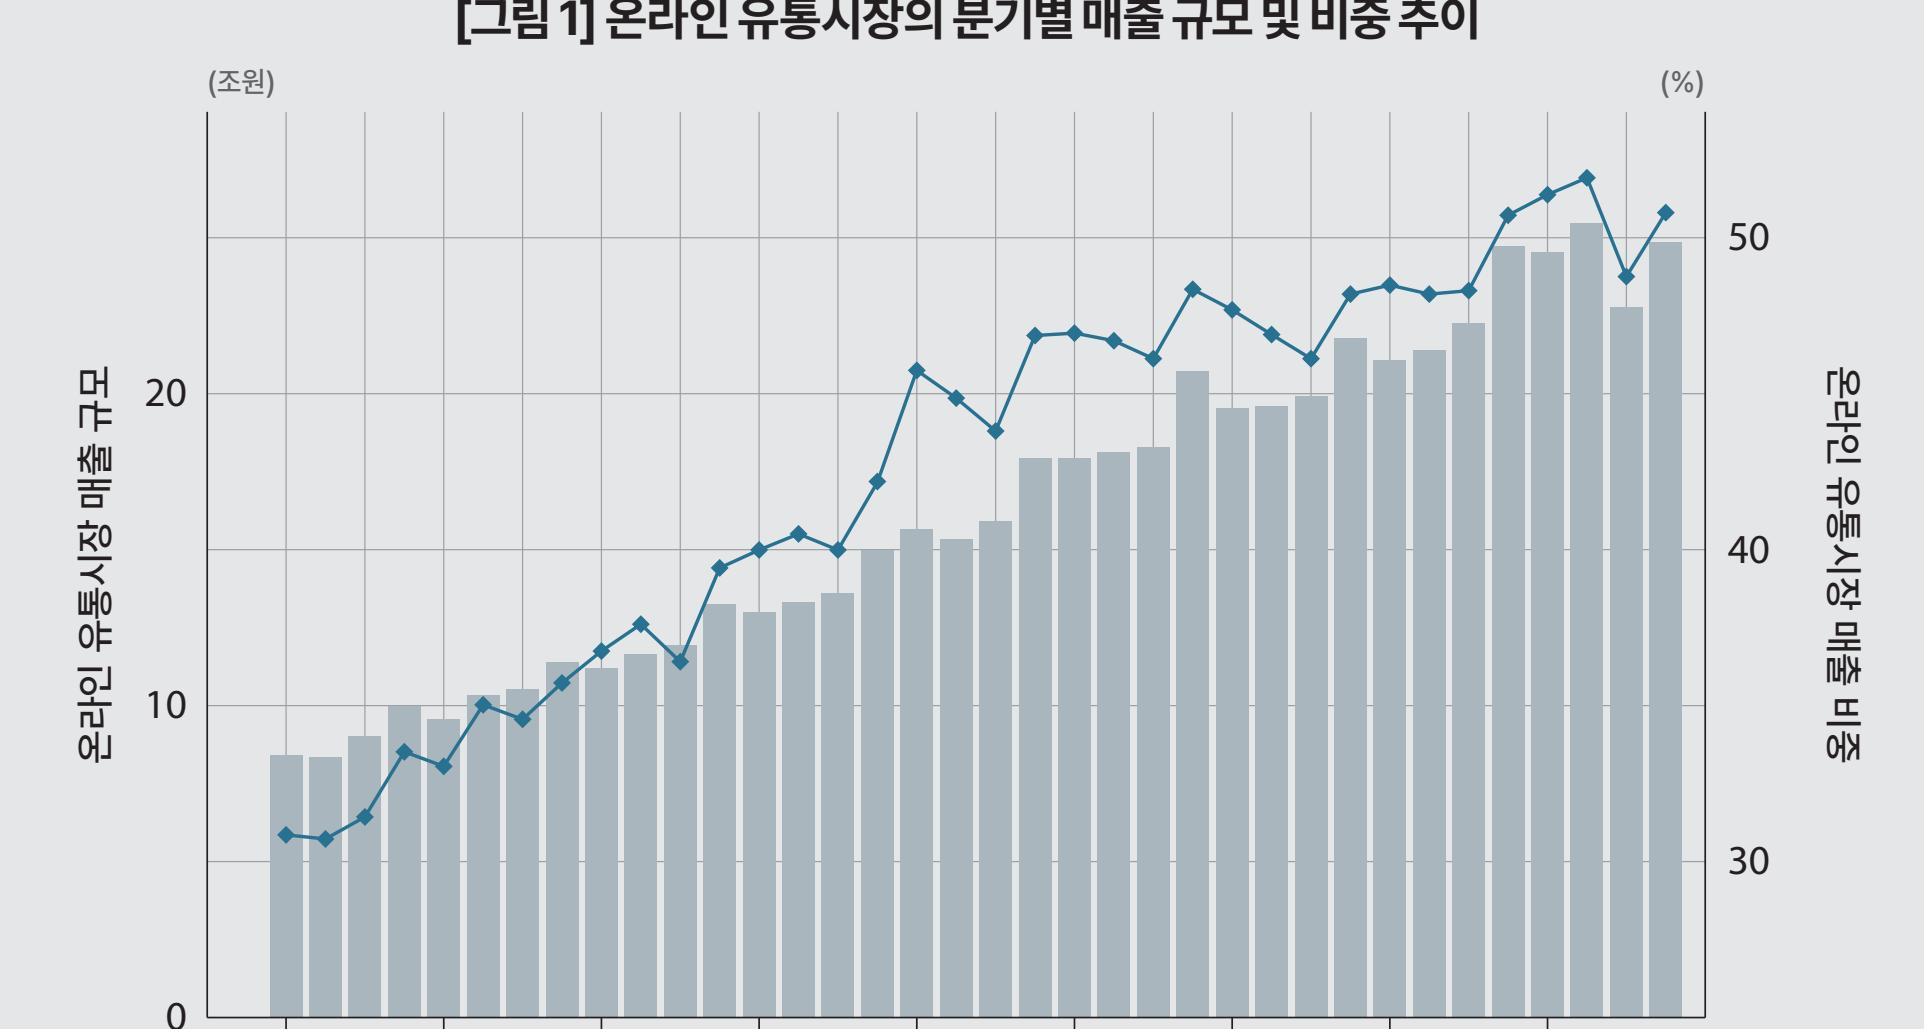

요약: [그림 1] 온라인 유통시장의 분기별 매출 규모 및 비중 추이. 

- Y축: 온라인 유통시장 매출 규모 (조원), 0~30 조원 범위.
- X축: 시간(분기).
- 추세: 전체적으로 매출 규모는 증가 추세를 보이며, 비중은 40%에서 55% 사이에서 변동함.



In [11]:
from IPython.display import Image, display

for i, (img_file, summary) in enumerate(zip(image_files, image_summaries)):
    print("=" * 60)
    print(f"[{i}] {img_file.name}")
    print("=" * 60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

In [12]:
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
  입력 : 10,478 토큰
  출력 : 1,796 토큰
  합계 : 12,274 토큰

요약한 이미지 수: 6 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


In [13]:
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "summaries.pkl")

저장 완료: c:\workspaces\RAG_Multimodal\multimodal-work\data\processed\summaries.pkl
